# Machine Learning Lab
## Experiment 03: Multiple Linear Regression

### 1. Aim
To implement a Multiple Linear Regression model for house price prediction using multiple features and evaluate the model using appropriate regression metrics.

### 7.1 Step 1: Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

### 7.2 Step 2: Load the Dataset
Load the CSV file using Pandas.

In [2]:
df = pd.read_csv(
    "ML_Lab_Multiple_Linear_Regression_House_Prices.csv"
)
print(df.head())

   Area_sqft  Bedrooms  Bathrooms  ...  Floor  Balconies  Price_Lakhs
0       1726         2          2  ...     10          3       168.54
1       2059         2          1  ...     10          3       185.35
2       1460         4          4  ...      0          3       183.25
3       1894         4          4  ...      0          0       187.83
4       1730         1          1  ...      1          2       158.35

[5 rows x 9 columns]


### 7.3 Step 3: Explore the Dataset
Display the basic information about the dataset.

In [3]:
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum())

(100, 9)
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Area_sqft             100 non-null    int64  
 1   Bedrooms              100 non-null    int64  
 2   Bathrooms             100 non-null    int64  
 3   Age_years             100 non-null    int64  
 4   Distance_to_Metro_km  100 non-null    float64
 5   Parking               100 non-null    int64  
 6   Floor                 100 non-null    int64  
 7   Balconies             100 non-null    int64  
 8   Price_Lakhs           100 non-null    float64
dtypes: float64(2), int64(7)
memory usage: 7.2 KB
None
         Area_sqft    Bedrooms   Bathrooms  ...      Floor   Balconies  Price_Lakhs
count   100.000000  100.000000  100.000000  ...  100.00000  100.000000   100.000000
mean   1572.580000    2.970000    2.780000  ...    4.44000    1.400000   162.241500
std     532.161652    1.473366 

### 7.4 Step 4: Separate Features and Target

In [4]:
features = [
    'Area_sqft',
    'Bedrooms',
    'Bathrooms',
    'Age_years',
    'Distance_to_Metro_km',
    'Parking',
    'Floor',
    'Balconies'
]
X = df[features]
y = df['Price_Lakhs']

### 7.5 Step 5: Split the Dataset
Divide the dataset into training and testing subsets.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

### 7.6 Step 6: Create the Model
Create an instance of the Linear Regression model.

In [6]:
model = LinearRegression()

### 7.7 Step 7: Train the Model
Train the model using the training data.

In [7]:
model.fit(X_train, y_train)

Out[0]: LinearRegression()


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 0.08, 5.95, 8.99,...,11.13, 1.2 , 2.62]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['Area_sqft','Bedrooms','Bathrooms',...,'Parking','Floor','Balconies']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.54
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,8


### 7.8 Step 8: Display Model Parameters
Display the intercept and coefficients.

In [8]:
print("Intercept:", model.intercept_)
for feature, coefficient in zip(
    features,
    model.coef_):
    print(feature, ":", coefficient)

Intercept: 1.5400586370310236
Area_sqft : 0.07809045505940766
Bedrooms : 5.949997374712874
Bathrooms : 8.99443079433506
Age_years : -1.110258088239795
Distance_to_Metro_km : -1.2684630748030248
Parking : 11.130570451499654
Floor : 1.1983501761790425
Balconies : 2.6170581819725562


### 7.9 Step 9: Generate Predictions
Use the trained model to predict prices for the test dataset.

In [9]:
y_pred = model.predict(X_test)
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})
print(comparison)

    Actual Price  Predicted Price
0         124.51       124.687037
1         186.08       191.461696
2         152.50       150.750720
3         154.34       171.626647
4         110.04        94.660165
5         137.79       162.789603
6         182.26       177.486600
7         128.19       154.835803
8          82.25        90.286583
9         168.54       179.292958
10        185.02       190.026167
11        125.71       118.550867
12        177.12       183.224096
13        166.09       152.438673
14        212.55       215.143411
15        158.35       157.187688
16        207.30       198.017060
17        176.61       183.729511
18        136.99       147.852328
19        156.87       168.839046


### 8.5 Calculate Evaluation Metrics

In [10]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 :", r2)

MAE : 9.504655704048737
MSE : 140.57588091637814
RMSE: 11.856470002339572
R2 : 0.8617742138229094


### 9. Actual vs Predicted Values
Create a scatter plot to compare actual and predicted house prices.

<ipython-input-1-bab83470ba90>:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


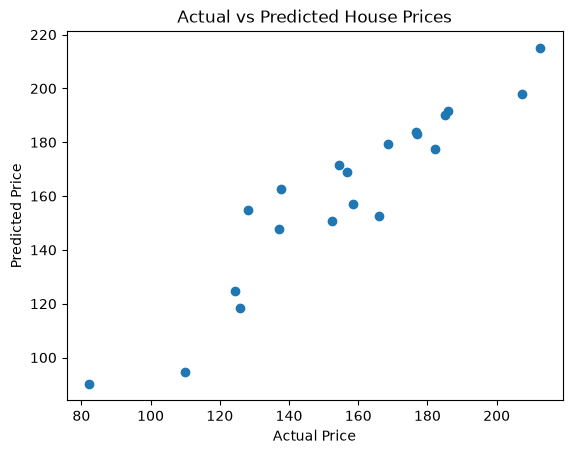

In [11]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title(
    "Actual vs Predicted House Prices"
)
plt.show()

### 10. Prediction for a New House

In [12]:
new_house = [[
    1800,
    3,
    2,
    5,
    3.5,
    1,
    5,
    2
]]
predicted_price = model.predict(new_house)
print(
    "Predicted House Price:",
    predicted_price[0],
    "Lakhs"
)

Predicted House Price: 190.307257950104 Lakhs


C:\Users\soham\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
